# Lab: Xây dựng web demo phân loại hoa Iris bằng Streamlit
**Họ tên:** Phạm Khanh  **MSSV:** SE204991  **Môn:** AIL303m – Machine Learning

Viết lại demo Gradio (`gr.Blocks`) thành **Streamlit**, giữ nguyên chức năng & bố cục 2 cột. Code được tách thành 3 phần:

| File | Vai trò |
|---|---|
| `iris_model.py` | **Huấn luyện + dự đoán** (GaussianNB trên toàn bộ Iris, không phụ thuộc Streamlit) |
| `app.py` | **Giao diện** Streamlit (2 cột, 4 slider, nút *Dự đoán ngay*, `@st.cache_resource`) |
| `make_images.py` | Tạo ảnh minh họa 3 loài vào `images/` |

Notebook này ghi các file trên bằng `%%writefile`, kiểm thử tự động, rồi chạy app **trên máy cá nhân** hoặc **Google Colab**.

## 0. Cài thư viện

In [1]:
!pip install -q streamlit scikit-learn pandas matplotlib numpy

## 1. Phần huấn luyện + dự đoán – `iris_model.py`

In [2]:
%%writefile iris_model.py
"""Phần HUẤN LUYỆN + DỰ ĐOÁN (không phụ thuộc Streamlit, có thể test độc lập).

- load_dataframe(): tải Iris dạng DataFrame (để xem bảng + vẽ biểu đồ)
- train_model()   : huấn luyện GaussianNB trên TOÀN BỘ dữ liệu Iris (giống bản Gradio)
- evaluate_holdout(): độ chính xác trên tập Test (chia 80/20, random_state=42, stratify=y)
- predict()       : dự đoán loài + xác suất 3 lớp cho một mẫu hoa
"""
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

# Đếm số lần train_model() thực sự chạy -> dùng để chứng minh @st.cache_resource hoạt động
# (module chỉ được import 1 lần nên biến này không bị reset khi Streamlit chạy lại script)
TRAIN_CALLS = 0


def load_iris_data():
    """Trả về (X, y, tên_cột_đặc_trưng, tên_loài) của tập Iris."""
    iris = load_iris()
    return iris.data, iris.target, list(iris.feature_names), [str(n) for n in iris.target_names]


def load_dataframe() -> pd.DataFrame:
    """Trả về DataFrame Iris gồm 4 đặc trưng + cột 'species' (tên loài)."""
    X, y, feature_names, target_names = load_iris_data()
    df = pd.DataFrame(X, columns=feature_names)
    df["species"] = [target_names[i] for i in y]
    return df


def train_model() -> GaussianNB:
    """Huấn luyện Gaussian Naive Bayes trên toàn bộ 150 mẫu Iris và trả về mô hình."""
    global TRAIN_CALLS
    TRAIN_CALLS += 1
    X, y, _, _ = load_iris_data()
    model = GaussianNB()
    model.fit(X, y)
    return model


def evaluate_holdout() -> float:
    """Độ chính xác trên tập Test: chia 80/20, random_state=42, stratify=y (tham chiếu ≈ 96.67%)."""
    X, y, _, _ = load_iris_data()
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    m = GaussianNB().fit(X_train, y_train)
    return float(accuracy_score(y_test, m.predict(X_test)))


def predict(model: GaussianNB, sepal_length, sepal_width, petal_length, petal_width):
    """Dự đoán loài hoa cho một mẫu.

    Input : model đã huấn luyện + 4 kích thước (cm).
    Output: (tên loài dạng chữ thường, dict {tên loài: xác suất}).
    """
    _, _, _, target_names = load_iris_data()
    x = np.array([[sepal_length, sepal_width, petal_length, petal_width]])
    pred_idx = int(model.predict(x)[0])
    proba = model.predict_proba(x)[0]
    return target_names[pred_idx], {target_names[i]: float(proba[i]) for i in range(len(target_names))}

Overwriting iris_model.py


## 2. Phần giao diện – `app.py`
Chú ý: Streamlit chạy lại toàn bộ file mỗi lần tương tác với widget, nên mô hình được huấn luyện trong hàm `get_model()` có `@st.cache_resource`.

In [3]:
%%writefile app.py
"""Phần GIAO DIỆN Streamlit – Demo phân loại hoa Iris (Gaussian Naive Bayes).

Chạy:  streamlit run app.py
Lưu ý: Streamlit chạy lại TOÀN BỘ file này mỗi khi người dùng tương tác với widget,
nên mô hình được huấn luyện trong hàm có @st.cache_resource (chỉ huấn luyện 1 lần).
"""
import os

import matplotlib.pyplot as plt
import streamlit as st

import iris_model as im

# ---------------------------------------------------------------- 1. Cấu hình trang
st.set_page_config(page_title="Iris Classification - Naive Bayes", page_icon="🌸", layout="wide")

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

# Ảnh minh họa của từng loài (đặt trong thư mục images/)
SPECIES_IMAGES = {
    "setosa": os.path.join(BASE_DIR, "images", "setosa.jpg"),
    "versicolor": os.path.join(BASE_DIR, "images", "versicolor.jpg"),
    "virginica": os.path.join(BASE_DIR, "images", "virginica.jpg"),
}

# Cấu hình 4 thanh trượt: (khóa, nhãn, min, max, mặc định, bước)
SLIDERS = [
    ("sl", "Chiều dài lá đài (Sepal Length - cm)", 4.0, 8.0, 5.1, 0.1),
    ("sw", "Chiều rộng lá đài (Sepal Width - cm)", 2.0, 4.5, 3.5, 0.1),
    ("pl", "Chiều dài cánh hoa (Petal Length - cm)", 1.0, 7.0, 1.4, 0.1),
    ("pw", "Chiều rộng cánh hoa (Petal Width - cm)", 0.1, 2.5, 0.2, 0.1),
]
SPECIES_COLORS = {"setosa": "#1f77b4", "versicolor": "#2ca02c", "virginica": "#d62728"}


# ---------------------------------------------------------------- 2. Cache mô hình / dữ liệu
@st.cache_resource(show_spinner="Đang huấn luyện mô hình Gaussian Naive Bayes...")
def get_model():
    """Huấn luyện GaussianNB đúng 1 lần; các lần rerun sau lấy lại từ cache."""
    return im.train_model()


@st.cache_data
def get_dataframe():
    """Bảng dữ liệu Iris (cache để không đọc lại)."""
    return im.load_dataframe()


@st.cache_data
def get_test_accuracy():
    """Độ chính xác trên tập Test 80/20 (cache vì không đổi)."""
    return im.evaluate_holdout()


# ---------------------------------------------------------------- 3. Các hàm hiển thị
def show_species_image(species: str):
    """Hiển thị ảnh minh họa; nếu thiếu file thì cảnh báo thay vì làm app bị dừng."""
    path = SPECIES_IMAGES[species]
    if os.path.exists(path):
        st.image(path, caption=f"Iris {species}", width=320)
    else:
        st.warning(f"Không tìm thấy ảnh minh họa: images/{os.path.basename(path)}")


def show_probabilities(probs: dict):
    """Hiển thị xác suất của cả 3 loài bằng thanh tiến trình."""
    for name, p in probs.items():
        st.progress(p, text=f"{name.capitalize()}: {p * 100:.2f}%")


def scatter_with_user_point(df, x_col, y_col, user_values):
    """Scatter plot phân bố 3 loài và đánh dấu điểm người dùng vừa nhập (nếu có)."""
    fig, ax = plt.subplots(figsize=(6, 4.2))
    for species, color in SPECIES_COLORS.items():
        sub = df[df["species"] == species]
        ax.scatter(sub[x_col], sub[y_col], c=color, label=species, alpha=0.7, s=28)
    if user_values is not None:
        names = list(df.columns[:4])
        ax.scatter(user_values[names.index(x_col)], user_values[names.index(y_col)],
                   marker="*", s=380, c="gold", edgecolors="black", linewidths=1.2,
                   label="Mẫu của bạn", zorder=5)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.legend()
    ax.grid(alpha=0.3)
    st.pyplot(fig)
    plt.close(fig)


# ---------------------------------------------------------------- 4. Giao diện chính
model = get_model()
df_iris = get_dataframe()

# Sidebar (bonus): thông tin mô hình
with st.sidebar:
    st.header("ℹ️ Thông tin mô hình")
    st.markdown(
        "- **Thuật toán:** Gaussian Naive Bayes\n"
        "- **Dữ liệu:** Iris (150 mẫu, 4 đặc trưng, 3 loài)\n"
        "- **Huấn luyện:** toàn bộ 150 mẫu"
    )
    st.metric("Accuracy trên tập Test (80/20)", f"{get_test_accuracy() * 100:.2f}%")
    st.caption("Chia train/test 80/20, random_state=42, stratify=y")
    st.metric("Số lần huấn luyện mô hình", im.TRAIN_CALLS,
              help="Luôn bằng 1 nhờ @st.cache_resource, dù kéo slider bao nhiêu lần.")

# Tiêu đề + dòng phụ + hướng dẫn
st.title("Demo Phân Loại Hoa Iris Dataset")
st.subheader("Mô hình: Gaussian Naive Bayes")
st.markdown("Nhập thông tin kích thước ở cột bên trái, bấm **Dự đoán ngay** để xem loài hoa tương ứng ở cột bên phải.")

col_left, col_right = st.columns(2)

# ---- Cột trái: đầu vào
with col_left:
    st.markdown("### Nhập thông tin mẫu hoa")
    values = [st.slider(label, mn, mx, default, step, key=key)
              for key, label, mn, mx, default, step in SLIDERS]
    clicked = st.button("🔍 Dự đoán ngay", type="primary")

# Khi bấm nút: dự đoán và lưu kết quả vào session_state
# (giống Gradio: kết quả giữ nguyên cho tới lần bấm nút tiếp theo, không đổi khi chỉ kéo slider)
if clicked:
    species, probs = im.predict(model, *values)
    st.session_state["result"] = {"species": species, "probs": probs, "values": values}

result = st.session_state.get("result")

# ---- Cột phải: kết quả (chỉ hiển thị sau khi đã bấm nút)
with col_right:
    st.markdown("### Kết quả dự đoán")
    if result is None:
        st.info("Chưa có kết quả. Hãy chọn kích thước và bấm **Dự đoán ngay**.")
    else:
        st.markdown(f"### Loài hoa được dự đoán: **{result['species'].upper()}**")
        show_species_image(result["species"])
        st.markdown("**Xác suất tương ứng từng loài**")
        show_probabilities(result["probs"])
        v = result["values"]
        st.caption(f"Đầu vào đã dùng: SL={v[0]}, SW={v[1]}, PL={v[2]}, PW={v[3]} (cm)")

# ---- Bonus: bảng dữ liệu + biểu đồ phân bố
st.divider()
tab_chart, tab_data = st.tabs(["📈 Biểu đồ phân bố", "📋 Bảng dữ liệu Iris"])
with tab_chart:
    feature_cols = list(df_iris.columns[:4])
    c1, c2 = st.columns(2)
    x_col = c1.selectbox("Trục X", feature_cols, index=2)
    y_col = c2.selectbox("Trục Y", feature_cols, index=3)
    c_plot, c_note = st.columns([3, 2])  # biểu đồ ở cột rộng, ghi chú ở cột hẹp để chữ không bị phóng to
    with c_plot:
        scatter_with_user_point(df_iris, x_col, y_col, result["values"] if result else None)
    with c_note:
        if result is None:
            st.caption("Bấm **Dự đoán ngay** để đánh dấu ⭐ mẫu của bạn trên biểu đồ.")
        else:
            st.markdown("⭐ là mẫu hoa bạn vừa nhập. Các loài càng tách xa nhau trên biểu đồ "
                        "thì mô hình càng dễ phân loại; điểm nằm giữa hai đám mây là vùng dễ nhầm.")
with tab_data:
    st.dataframe(df_iris)

Overwriting app.py


## 3. Tạo ảnh minh họa 3 loài (`images/`)
Nếu có ảnh thật, chép đè `images/setosa.jpg`, `versicolor.jpg`, `virginica.jpg`. Thiếu ảnh thì app chỉ hiện cảnh báo (bonus) chứ không bị dừng.

In [4]:
%%writefile make_images.py
"""Tạo 3 ảnh MINH HỌA (vẽ bằng matplotlib) cho 3 loài Iris vào thư mục images/.

Đây là hình vẽ cách điệu, không phải ảnh chụp thật. Muốn dùng ảnh thật chỉ cần chép đè
images/setosa.jpg, images/versicolor.jpg, images/virginica.jpg.
"""
import os

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# (màu cánh đứng, màu cánh rủ, màu vệt giữa, độ to cánh, nền)
STYLE = {
    "setosa": ("#6a5acd", "#4b3fb5", "#f4e04d", 0.8, "#e8f1fb"),
    "versicolor": ("#8e44ad", "#6c3483", "#f1c40f", 1.0, "#eef7ec"),
    "virginica": ("#4a2c8a", "#2e1a5e", "#f5b041", 1.25, "#fbeff1"),
}


def draw(species: str, out_dir: str = "images"):
    """Vẽ một bông hoa Iris cách điệu: 3 cánh đứng + 3 cánh rủ + thân + lá."""
    up, down, streak, s, bg = STYLE[species]
    fig, ax = plt.subplots(figsize=(4.8, 3.6), dpi=130)
    ax.set_xlim(-3, 3); ax.set_ylim(-2.4, 2.4); ax.set_aspect("equal"); ax.axis("off")
    fig.patch.set_facecolor(bg)
    ax.plot([0, 0.1], [-2.4, -0.2], c="#2e7d32", lw=5, solid_capstyle="round")   # thân
    ax.add_patch(Ellipse((-0.9, -1.5), 0.45, 1.8, angle=25, fc="#43a047", ec="none"))  # lá
    ax.add_patch(Ellipse((0.9, -1.5), 0.45, 1.8, angle=-25, fc="#388e3c", ec="none"))
    for ang in (90, 210, 330):          # 3 cánh đứng
        ax.add_patch(Ellipse((0, 0), 0.9 * s, 1.9 * s, angle=ang - 90, fc=up, ec="none", alpha=0.9))
    for ang in (270, 30, 150):          # 3 cánh rủ
        ax.add_patch(Ellipse((0, 0), 1.1 * s, 1.7 * s, angle=ang - 90, fc=down, ec="none", alpha=0.9))
        ax.add_patch(Ellipse((0, 0), 0.18 * s, 1.0 * s, angle=ang - 90, fc=streak, ec="none"))
    ax.add_patch(plt.Circle((0, 0), 0.18, fc="#fff3b0", ec="none"))
    os.makedirs(out_dir, exist_ok=True)
    fig.savefig(os.path.join(out_dir, f"{species}.jpg"), facecolor=bg)
    plt.close(fig)


if __name__ == "__main__":
    for sp in STYLE:
        draw(sp)
    print("Đã tạo ảnh minh họa trong images/")

Overwriting make_images.py


In [5]:
!python make_images.py && ls -la images

Đã tạo ảnh minh họa trong images/


total 44
drwxr-xr-x 2 root root  4096 Nov 12 01:22 .
drwxr-xr-x 5 root root  4096 Nov 12 01:23 ..
-rw-r--r-- 1 root root  9861 Nov 12 01:23 setosa.jpg
-rw-r--r-- 1 root root 10186 Nov 12 01:23 versicolor.jpg
-rw-r--r-- 1 root root 11058 Nov 12 01:23 virginica.jpg


## 4. Kiểm thử tự động (`AppTest`)
Kiểm tra: chưa bấm nút thì chưa có kết quả; 3 ca bắt buộc; mô hình chỉ huấn luyện **1 lần** dù rerun nhiều lần; thiếu ảnh không làm app lỗi.

In [6]:
%%writefile test_app.py
"""Kiểm thử tự động bằng streamlit.testing.v1.AppTest (chạy: python test_app.py)."""
from streamlit.testing.v1 import AppTest

import iris_model as im

CASES = [  # (SL, SW, PL, PW, loài mong đợi)
    (5.1, 3.5, 1.4, 0.2, "setosa"),
    (6.0, 2.9, 4.5, 1.5, "versicolor"),
    (6.5, 3.0, 5.8, 2.2, "virginica"),
]


def run_case(sl, sw, pl, pw):
    at = AppTest.from_file("app.py", default_timeout=30).run()
    assert not at.exception, at.exception
    for key, v in zip(("sl", "sw", "pl", "pw"), (sl, sw, pl, pw)):
        at.slider(key=key).set_value(v)
    at.button[0].click().run()
    assert not at.exception, at.exception
    return at


if __name__ == "__main__":
    # 1. Trước khi bấm nút: chưa có kết quả
    at0 = AppTest.from_file("app.py", default_timeout=30).run()
    assert not at0.exception and len(at0.slider) == 4 and len(at0.columns) >= 2
    assert not any("được dự đoán" in m.value for m in at0.markdown), "Kết quả không được hiện trước khi bấm nút"
    print("✔ Chưa bấm nút -> chưa hiện kết quả; có 4 slider, 2 cột")

    # 2. Ba ca kiểm thử bắt buộc
    for sl, sw, pl, pw, exp in CASES:
        at = run_case(sl, sw, pl, pw)
        txt = " ".join(m.value for m in at.markdown)
        assert f"**{exp.upper()}**" in txt, (sl, sw, pl, pw, txt)
        assert len(at.get("progress")) == 3
        print(f"✔ ({sl}, {sw}, {pl}, {pw}) -> {exp.upper()}")

    # 4. Cache: sau nhiều lần rerun mô hình vẫn chỉ huấn luyện 1 lần
    at = run_case(*CASES[1][:4])
    at.slider(key="sl").set_value(7.0).run()
    at.slider(key="pl").set_value(6.0).run()
    assert im.TRAIN_CALLS == 1, im.TRAIN_CALLS
    print(f"✔ Sau nhiều lần bấm nút / kéo slider, train_model() chỉ chạy {im.TRAIN_CALLS} lần (cache hoạt động)")

    # 3. Ca nằm giữa 2 loài
    sp, pr = im.predict(im.train_model(), 6.0, 2.7, 5.0, 1.7)
    print("✔ Ca giữa 2 loài (6.0, 2.7, 5.0, 1.7):", sp, {k: f"{v:.2%}" for k, v in pr.items()})

    # 5. Xử lý thiếu ảnh: không văng lỗi, hiện warning
    import os, shutil
    shutil.move("images/setosa.jpg", "images/_bak.jpg")
    try:
        at = run_case(5.1, 3.5, 1.4, 0.2)
        assert len(at.warning) == 1 and "Không tìm thấy ảnh" in at.warning[0].value
        print("✔ Thiếu file ảnh -> cảnh báo, app vẫn chạy")
    finally:
        shutil.move("images/_bak.jpg", "images/setosa.jpg")
    print("\nTẤT CẢ TEST ĐỀU ĐẠT")

Overwriting test_app.py


In [7]:
!python test_app.py 2>&1 | grep -E "✔|TẤT CẢ|Error|Traceback"

✔ Chưa bấm nút -> chưa hiện kết quả; có 4 slider, 2 cột


✔ (5.1, 3.5, 1.4, 0.2) -> SETOSA


✔ (6.0, 2.9, 4.5, 1.5) -> VERSICOLOR


✔ (6.5, 3.0, 5.8, 2.2) -> VIRGINICA


✔ Sau nhiều lần bấm nút / kéo slider, train_model() chỉ chạy 1 lần (cache hoạt động)
✔ Ca giữa 2 loài (6.0, 2.7, 5.0, 1.7): virginica {'setosa': '0.00%', 'versicolor': '40.99%', 'virginica': '59.01%'}


✔ Thiếu file ảnh -> cảnh báo, app vẫn chạy
TẤT CẢ TEST ĐỀU ĐẠT


## 5. Chạy ứng dụng

**Trên máy cá nhân** (terminal, trong thư mục chứa `app.py`):
```bash
pip install -r requirements.txt
streamlit run app.py
```
Mở http://localhost:8501.

**Trên Google Colab:** chạy ô dưới – ô này khởi động Streamlit ở nền; nếu đang trong Colab sẽ mở thêm tunnel `localtunnel` (nhập mật khẩu là IP công khai được in ra).

In [8]:
import subprocess, sys, time, urllib.request

# Khởi động Streamlit ở chế độ nền
server = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app.py", "--server.headless", "true",
     "--server.port", "8501", "--browser.gatherUsageStats", "false"],
    stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT,
)

# Chờ server sẵn sàng bằng endpoint health
for _ in range(30):
    try:
        ok = urllib.request.urlopen("http://localhost:8501/_stcore/health", timeout=2).read()
        print("Streamlit đã chạy tại http://localhost:8501  (health:", ok.decode(), ")")
        break
    except Exception:
        time.sleep(1)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Colab không mở được localhost từ trình duyệt -> dùng localtunnel
    !npm install -q localtunnel
    print("Mật khẩu tunnel (IP công khai):")
    !curl -s ipv4.icanhazip.com
    !npx localtunnel --port 8501
else:
    print("Chạy local: mở trình duyệt tại http://localhost:8501 (dừng server: server.terminate())")
    server.terminate()   # trong lúc nộp/kiểm thử tự động thì tắt server sau khi xác nhận chạy được

Streamlit đã chạy tại http://localhost:8501  (health: ok )
Chạy local: mở trình duyệt tại http://localhost:8501 (dừng server: server.terminate())


## 6. Báo cáo kiểm thử (ảnh chụp màn hình)

Trước khi bấm nút (chưa có kết quả)


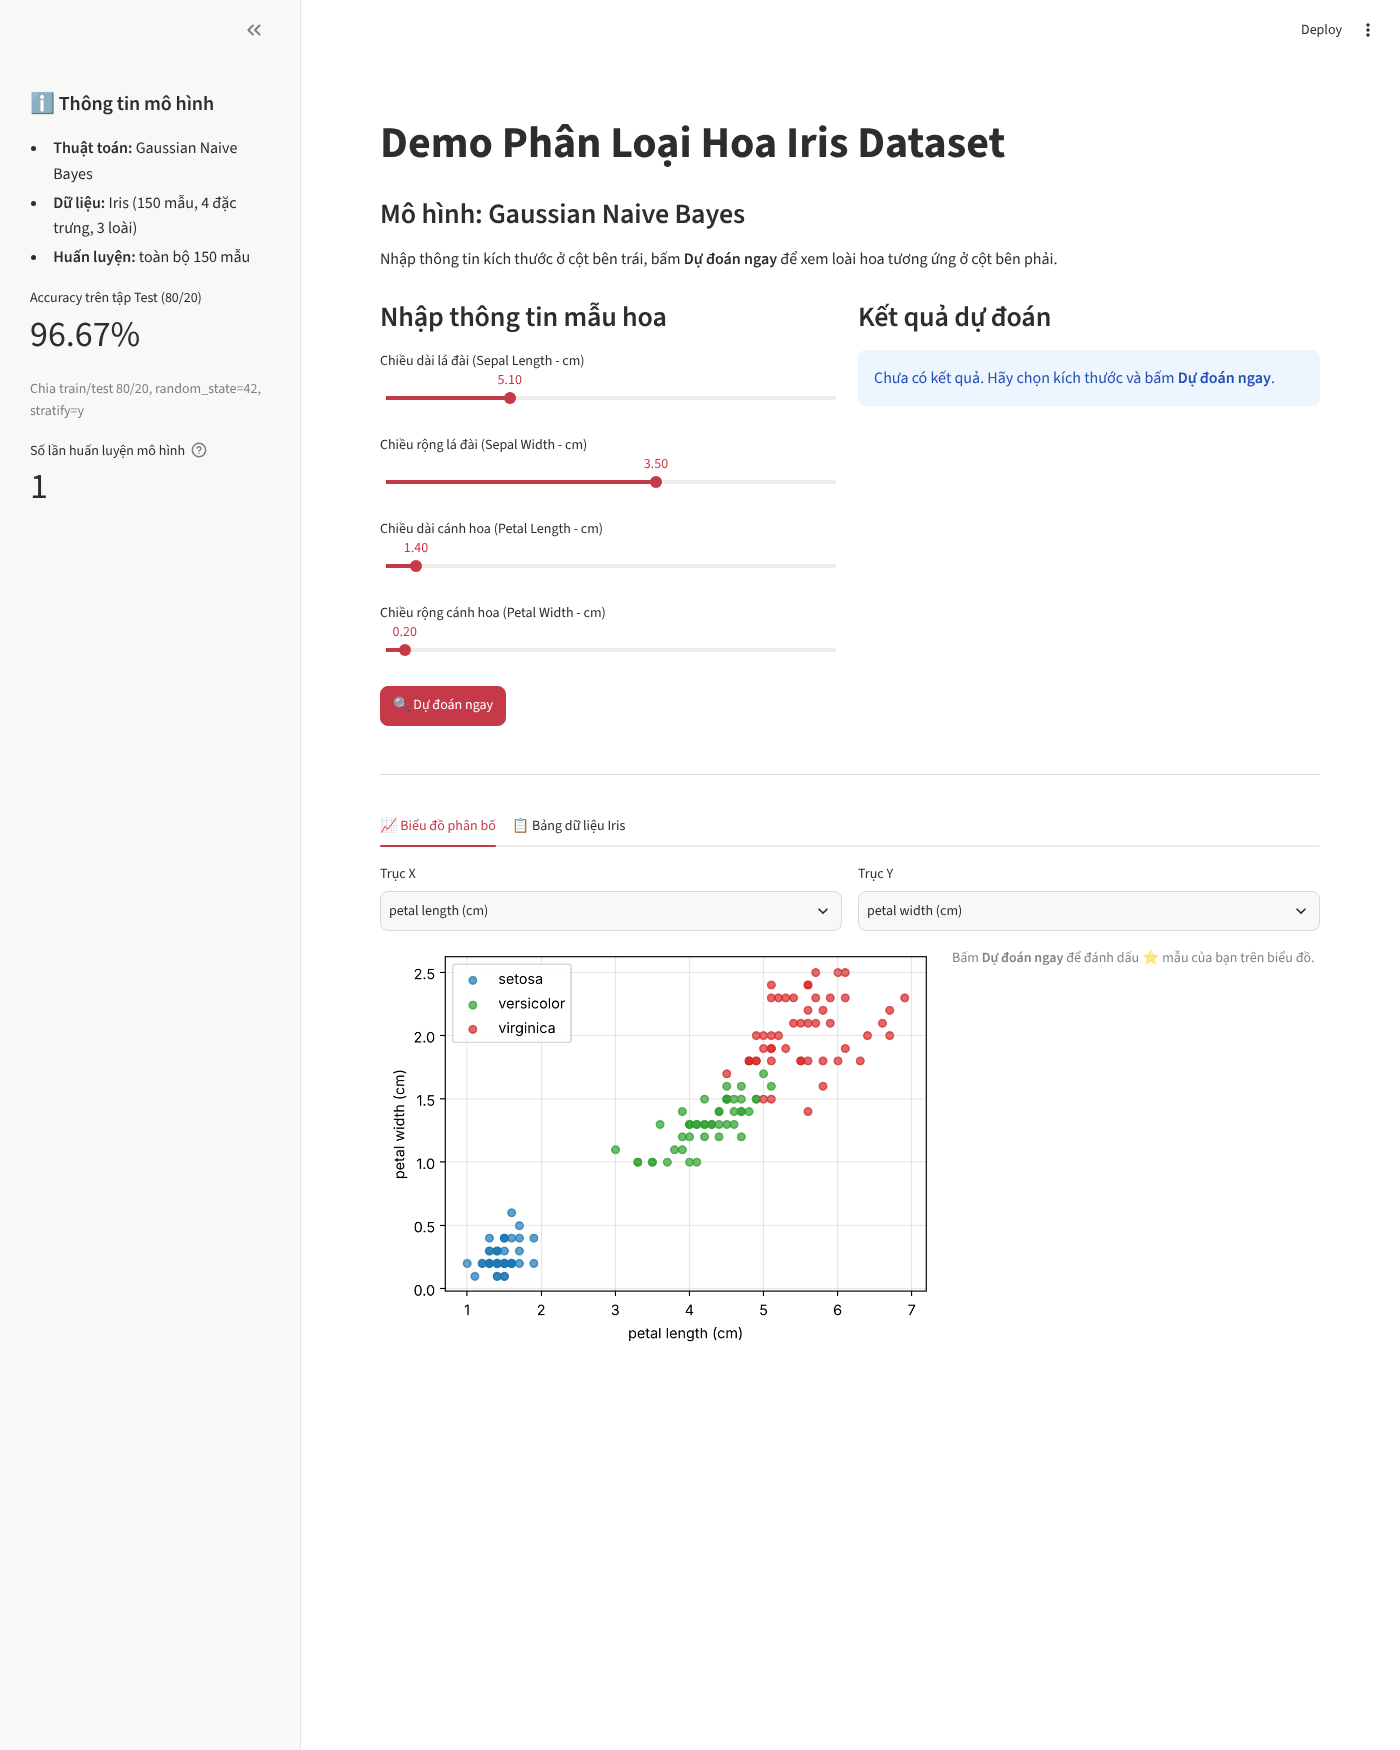

Test 1: 5.1, 3.5, 1.4, 0.2 -> Setosa


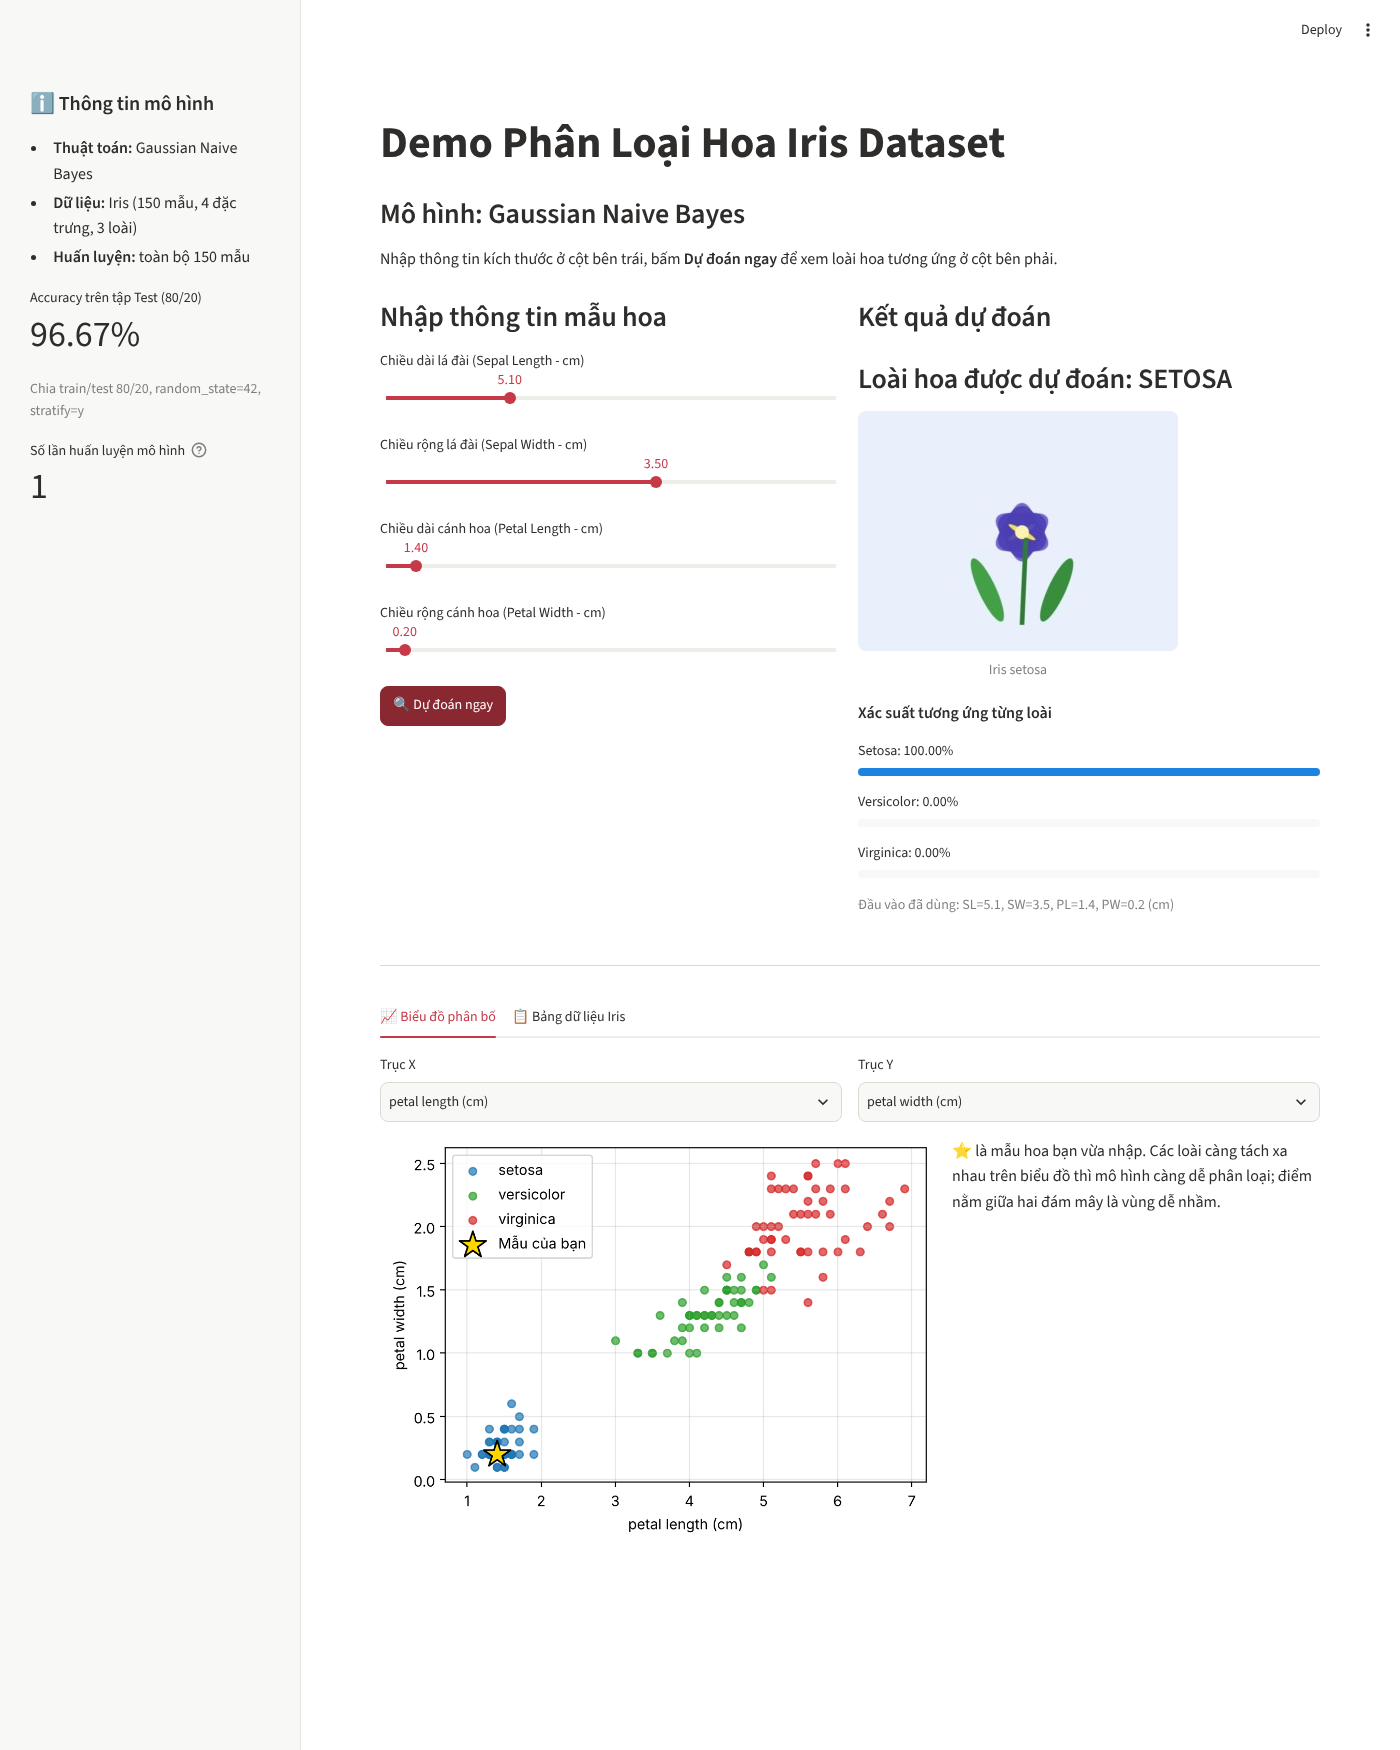

Test 2: 6.0, 2.9, 4.5, 1.5 -> Versicolor


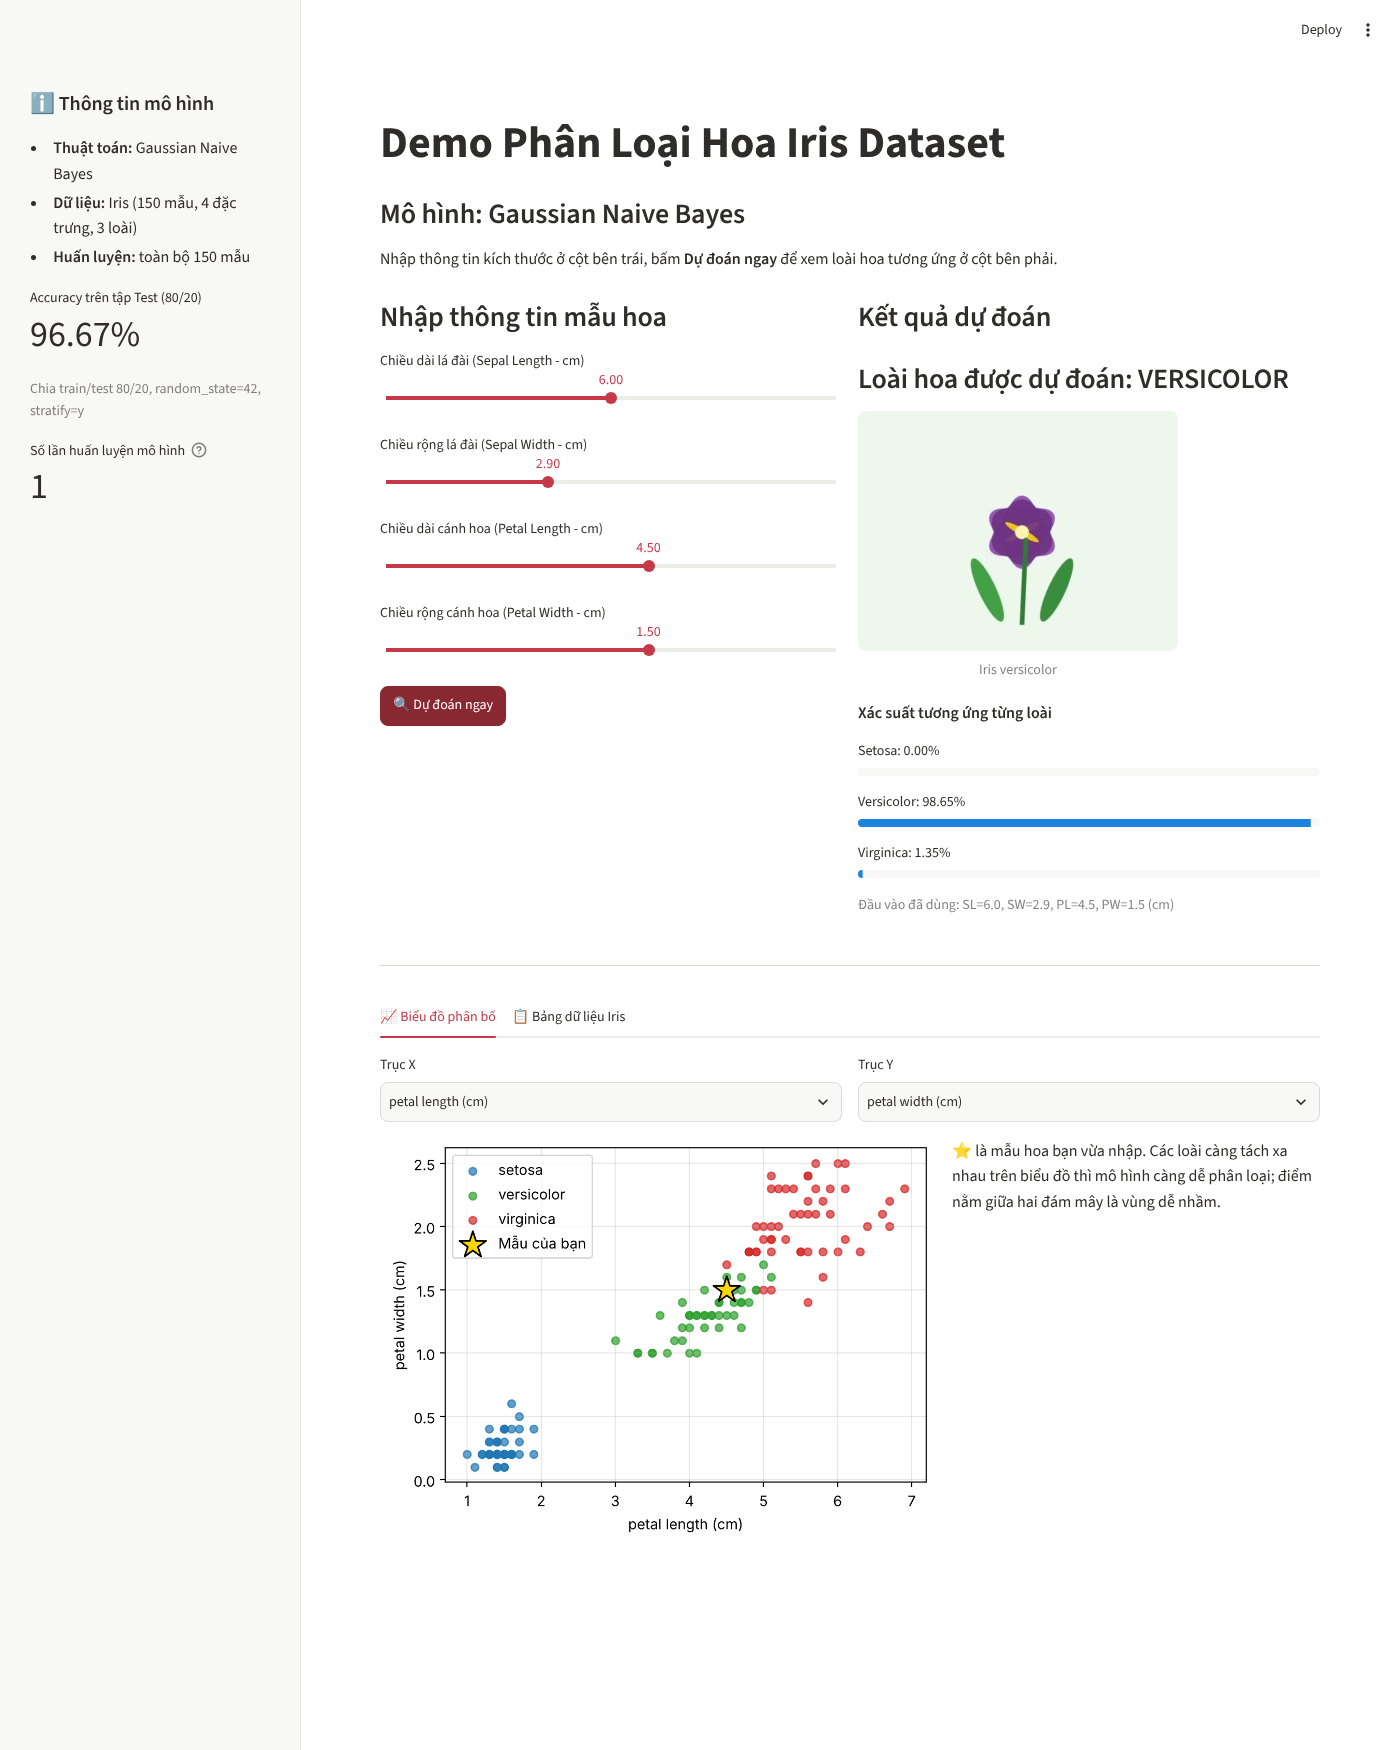

Test 3: 6.5, 3.0, 5.8, 2.2 -> Virginica


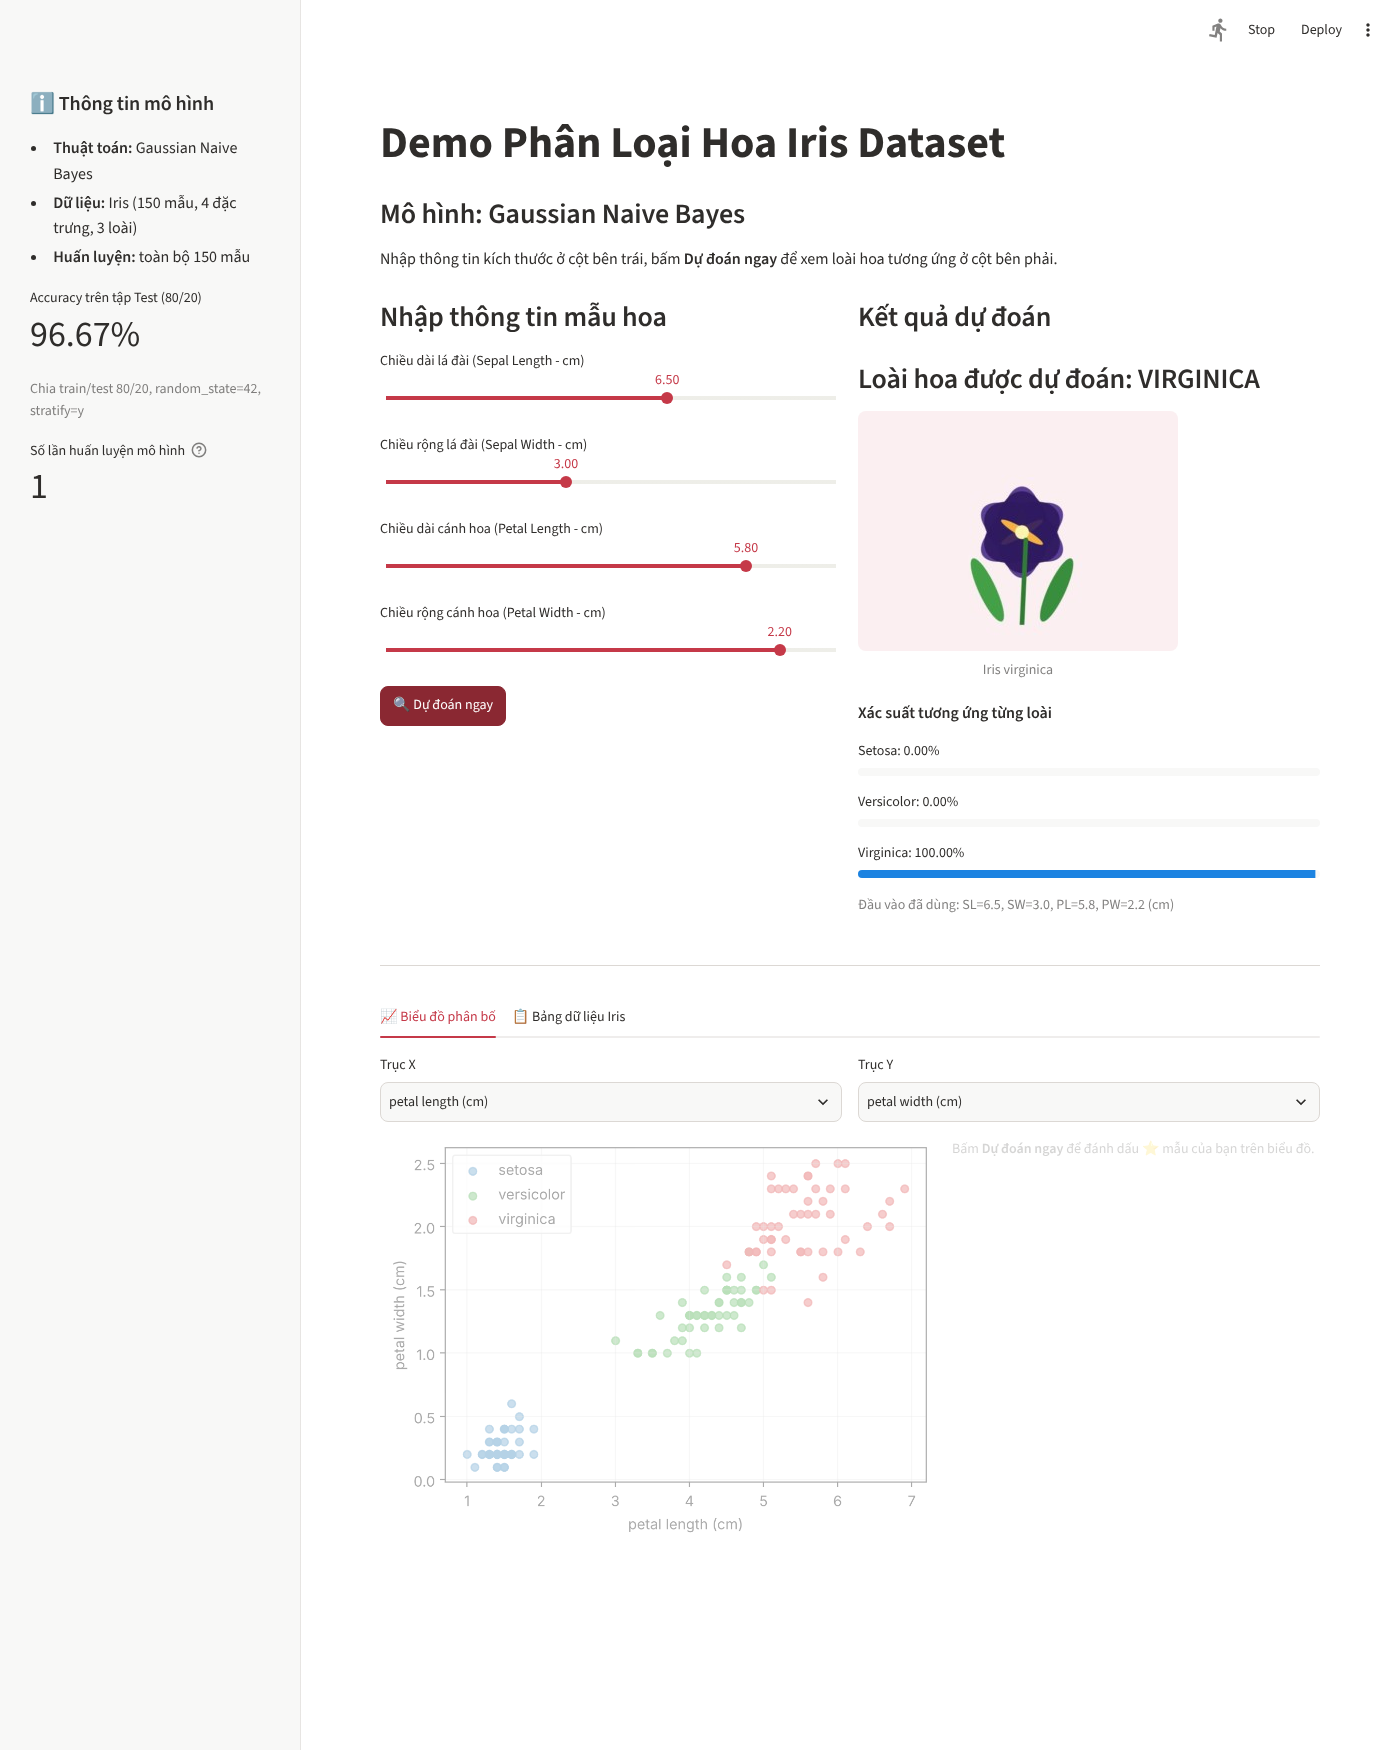

Test 4: 6.0, 2.7, 5.0, 1.7 -> giữa 2 loài


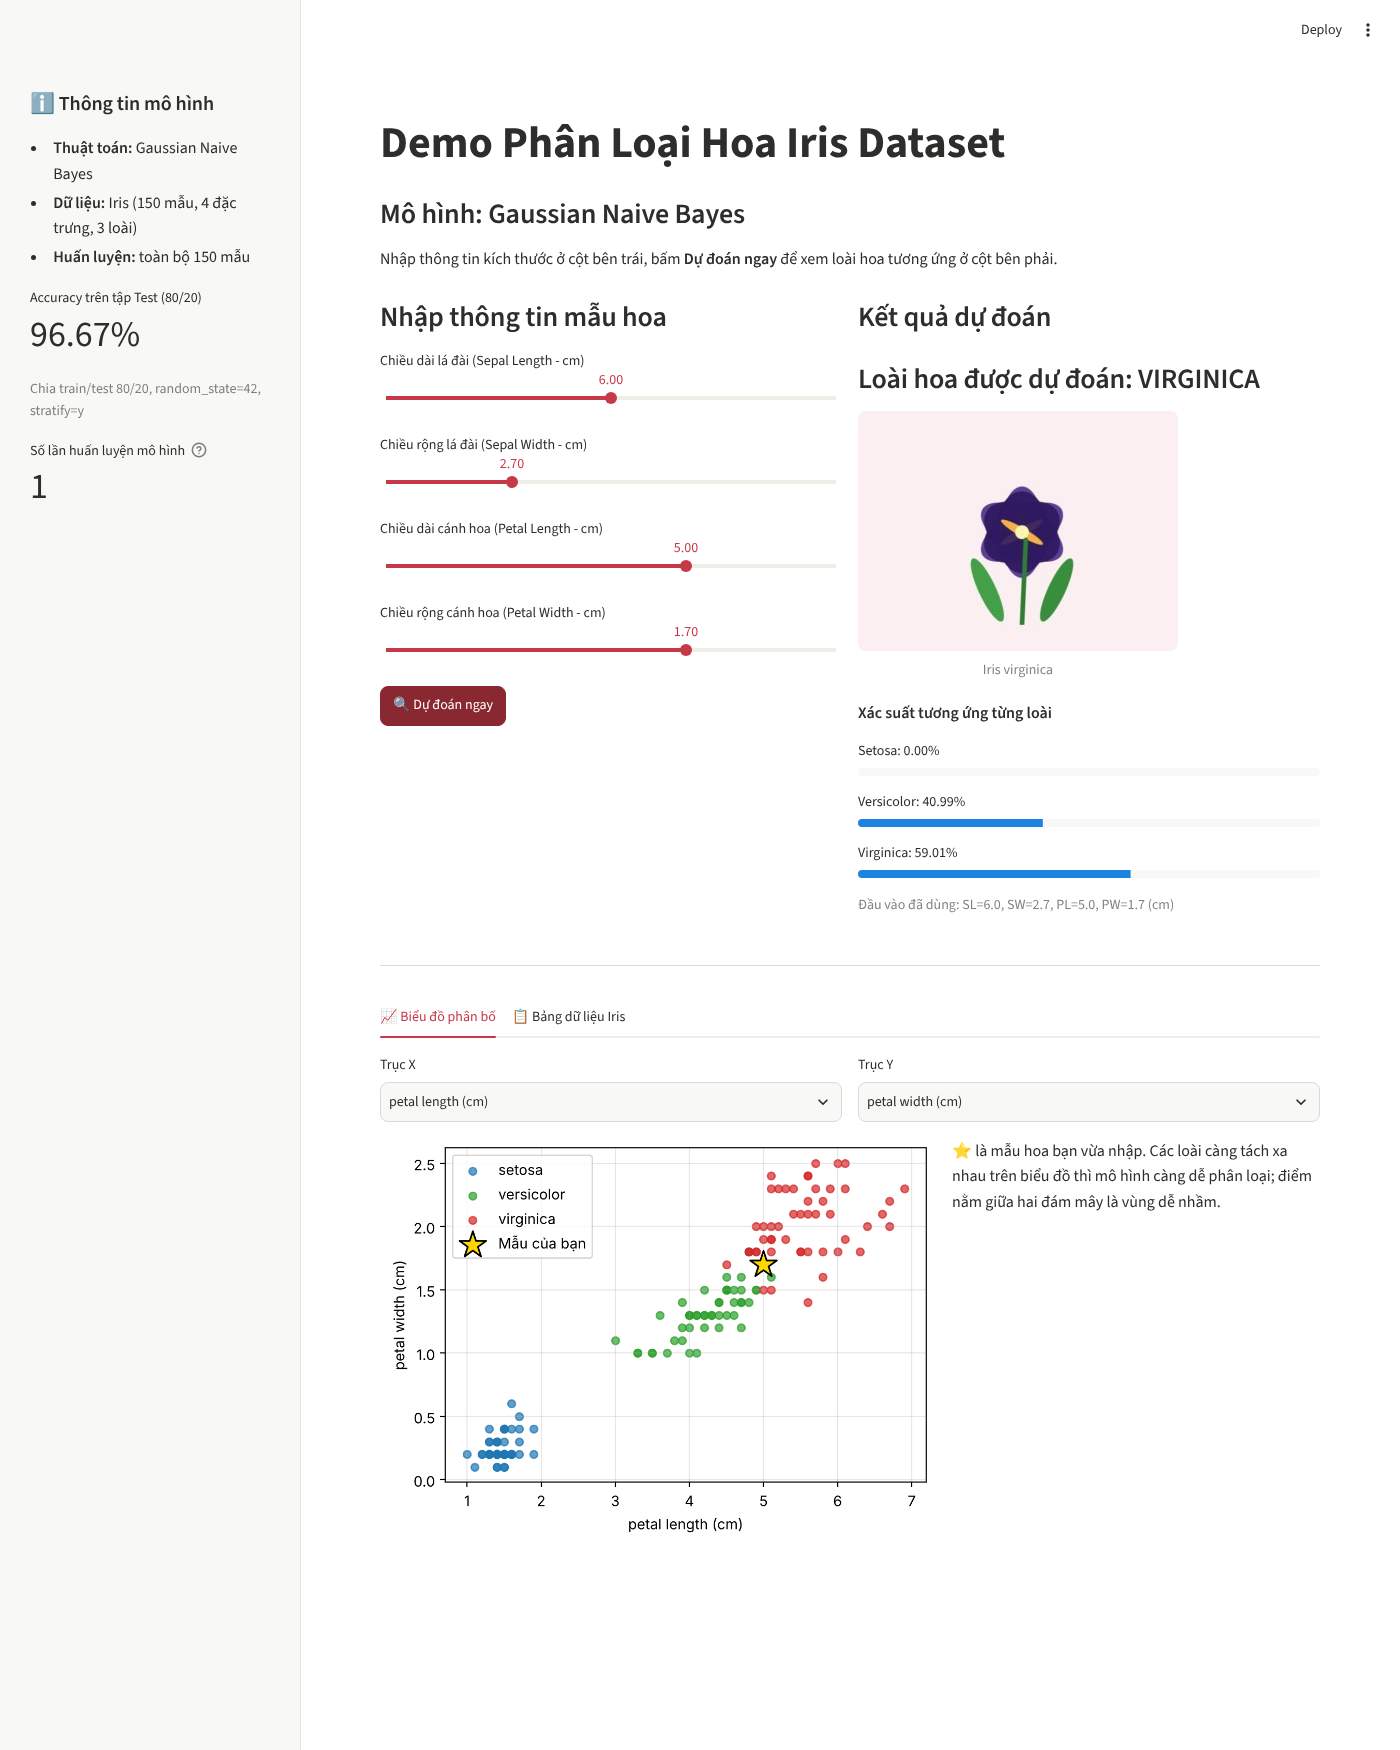

In [9]:
from pathlib import Path
from IPython.display import Image, display

shots = [("Trước khi bấm nút (chưa có kết quả)", "test0_truoc_khi_bam.png"),
         ("Test 1: 5.1, 3.5, 1.4, 0.2 -> Setosa", "test1_setosa.png"),
         ("Test 2: 6.0, 2.9, 4.5, 1.5 -> Versicolor", "test2_versicolor.png"),
         ("Test 3: 6.5, 3.0, 5.8, 2.2 -> Virginica", "test3_virginica.png"),
         ("Test 4: 6.0, 2.7, 5.0, 1.7 -> giữa 2 loài", "test4_giua_2_loai.png")]
for title, fn in shots:
    p = Path("screenshots") / fn
    if p.exists():
        print(title); display(Image(filename=str(p), width=800))

| STT | Đầu vào (SL, SW, PL, PW) | Kết quả mong đợi | Kết quả thực tế | Xác suất (setosa / versicolor / virginica) |
|---|---|---|---|---|
| 1 | 5.1, 3.5, 1.4, 0.2 | Setosa | **SETOSA** ✔ | 100.00% / 0.00% / 0.00% |
| 2 | 6.0, 2.9, 4.5, 1.5 | Versicolor | **VERSICOLOR** ✔ | 0.00% / 98.65% / 1.35% |
| 3 | 6.5, 3.0, 5.8, 2.2 | Virginica | **VIRGINICA** ✔ | 0.00% / 0.00% / 100.00% |
| 4 | 6.0, 2.7, 5.0, 1.7 | (giữa 2 loài) | **VIRGINICA** | 0.00% / **40.99%** / **59.01%** |

**Nhận xét ca 4:** mẫu có petal length 5.0 và petal width 1.7 nằm ở vùng chồng lấn giữa Versicolor và Virginica (xem biểu đồ phân bố trong app). Mô hình vẫn chọn Virginica nhưng chỉ với 59,01%, còn Versicolor chiếm tới 40,99%; Setosa gần như 0% vì đã tách hẳn khỏi hai loài kia. Hai loài này cách nhau chưa đến 20 điểm phần trăm nên dự đoán kém chắc chắn, khác hẳn các ca 1–3 (xác suất ≥ 98,65%). Điều này khớp với việc mô hình chỉ đạt 96,67% trên tập Test: các mẫu bị nhầm đều nằm giữa Versicolor và Virginica.

## 7. So sánh Gradio và Streamlit
| Chức năng | Gradio | Streamlit |
|---|---|---|
| Mô hình lập trình | Hàm + sự kiện (`inputs → fn → outputs`), chỉ chạy hàm khi có sự kiện | Chạy lại **toàn bộ file** mỗi lần tương tác → phải dùng `@st.cache_resource` |
| Nút bấm | `gr.Button` + `.click(...)` | `st.button` trả về `True` đúng lần bấm |
| Giữ kết quả | Output tự giữ đến lần click sau | Phải lưu vào `st.session_state` |
| Bố cục | `gr.Row()` + `gr.Column()` | `st.columns(2)`, `st.sidebar`, `st.tabs` |
| Xác suất | `gr.Label` | `st.progress`, `st.bar_chart` |
| Chạy | `demo.launch()` | `streamlit run app.py` |

Streamlit linh hoạt hơn khi làm trang nhiều thành phần (sidebar, tab, biểu đồ), còn Gradio gọn hơn nếu chỉ cần demo nhanh một hàm.

## 8. Bonus đã làm
- Sidebar: thông tin mô hình, accuracy trên tập Test 80/20 (`random_state=42`, `stratify=y`) = **96.67%**, bộ đếm số lần huấn luyện (luôn = 1).
- Tab *Bảng dữ liệu Iris* (`st.dataframe`) và tab *Biểu đồ phân bố* (scatter, chọn trục, đánh dấu ⭐ điểm vừa nhập).
- Thiếu file ảnh → `st.warning`, app không dừng.